In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sb

pokemon = pd.read_csv('./bar_chart_datasets/pokemon.csv')

A histogram is used to plot the distribution of a numeric variable. It's the quantitative version of the bar chart. However, rather than plotting one bar for each unique numeric value, values are grouped into continuous bins, and one bar for each bin is plotted to depict the number. You can use either Matplotlib or Seaborn to plot the histograms. There is a mild variation in the specifics, such as plotting a Kernel Density Estimate (KDE) line along with bars using Seaborn's histplot() function, and the arguments that you can use in either case.

Matplotlib.pyplot.hist()
You can use the default settings for matplotlib's hist()(opens in a new tab) function to plot a histogram with 10 bins:

Example 1. Plot a default histogram

In [17]:
pokemon.head(10)

,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,49,45,65,65
1,2,ivysaur,1,1.0,13.0,142,grass,poison,60,62,63,60,80,80
2,3,venusaur,1,2.0,100.0,236,grass,poison,80,82,83,80,100,100
3,4,charmander,1,0.6,8.5,62,fire,NaN,39,52,43,65,60,50
4,5,charmeleon,1,1.1,19.0,142,fire,NaN,58,64,58,80,80,65
5,6,charizard,1,1.7,90.5,240,fire,flying,78,84,78,100,109,85
6,7,squirtle,1,0.5,9.0,63,water,NaN,44,48,65,43,50,64
7,8,wartortle,1,1.0,22.5,142,water,NaN,59,63,80,58,65,80
8,9,blastoise,1,1.6,85.5,239,water,NaN,79,83,100,78,85,105
9,10,caterpie,1,0.3,2.9,39,bug,NaN,45,30,35,45,20,20


In [16]:
pokemon['speed'].describe()

count    807.000000
mean      65.830235
std       27.736838
min        5.000000
25%       45.000000
50%       65.000000
75%       85.000000
max      160.000000
Name: speed, dtype: float64

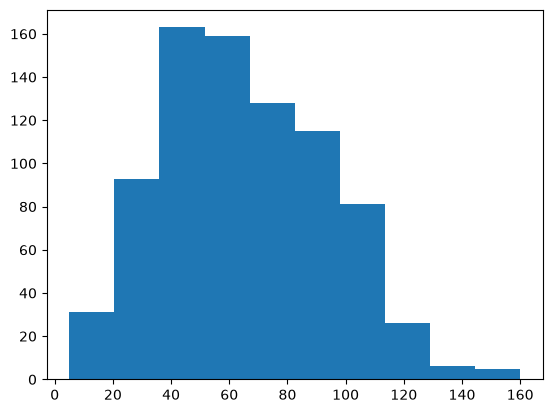

In [13]:
plt.hist(data=pokemon, x='speed');

Overall, a generally bimodal distribution is observed (one with two peaks or humps). The direct adjacency of the bars in the histogram, in contrast to the separated bars in a bar chart, emphasizes the fact that the data takes on a continuous range of values. When a data value is on a bin edge, it is counted in the bin to its right. The exception is the rightmost bin edge, which places data values equal to the uppermost limit into the right-most bin (to the upper limit's left).

By default, the hist function divides the data into 10 bins, based on the range of values taken. In almost every case, we will want to change these settings. Usually, having only ten bins is too few to really understand the distribution of the data. And the default tick marks are often not on nice, 'round' values that make the ranges taken by each bin easy to interpret.

Wouldn't it be better if I said "between 0 and 2.5" instead of "between about 0 and 2.5", and "from 2.5 to 5" instead of "from about 2.5 to 5" above?

You can use descriptive statistics (e.g. via dataframe['column'].describe()(opens in a new tab)) to gauge what minimum and maximum bin limits might be appropriate for the plot. These bin edges can be set using numpy's arange(opens in a new tab) function:

Example 2. Histogram with fixed number of bins

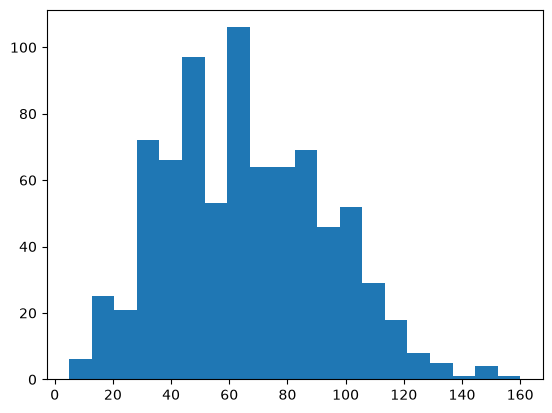

In [15]:
plt.hist(data=pokemon, x='speed', bins=20);

Example 3. Histogram with dynamic number of bins

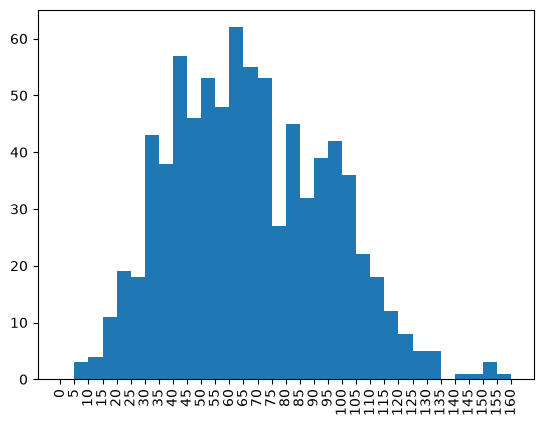

In [ ]:
# Create bins with a step size of 5

bins = np.arange(0, pokemon['speed'].max()+5, 5)

#plot a histogram using the defined bins

plt.hist(data=pokemon, x='speed', bins = bins)

plt.xticks(bins, rotation=90)

plt.show()

The first argument to arange is the leftmost bin edge, the second argument the upper limit, and the third argument the bin width. Note that even though I've specified the "max" value in the second argument, I've added a "+5" (the bin width). That is because arange will only return values that are strictly less than the upper limit. Adding in "+5" is a safety measure to ensure that the rightmost bin edge is at least the maximum data value, so that all of the data points are plotted. The leftmost bin is set as a hardcoded value to get a nice, interpretable value, though you could use functions like numpy's around(opens in a new tab) if you wanted to approach that end programmatically.

Alternative Approach - Seaborn’s histplot()
This function can also plot histograms, similar to the pyplot.hist() function, and is integrated with other univariate plotting features. It allows specifying a data source and column as separate arguments, like we’ve seen with countplot and hist.

The basic syntax is:

seaborn.histplot(data=DataFrame, x='ColumnName', bins=Number, kde=Boolean)

Example 4. Plot the similar histogram with Seaborn’s histplot()

<Axes: xlabel='speed', ylabel='Density'>

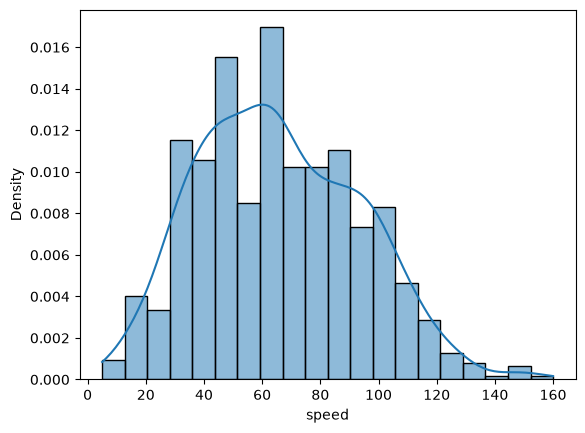

In [33]:
# Plot a histogram with KDE (Kernel Density Estimate) line

sb.histplot(data=pokemon, x='speed', stat='density', kde=True, bins=20)



The histplot function provides built-in rules for specifying histogram bins and includes an option to overlay a kernel density estimate (KDE) curve on the data using the kde parameter. By default, the histogram’s vertical axis reflects the count of data points in each bin. However, if the stat='density' option is used, the vertical axis is normalized so that the total area of the histogram equals 1, making it comparable to the KDE curve. This normalization ensures that the histogram and KDE curve can be meaningfully compared. For more details on KDEs, refer to additional resources provided in this lesson.

While the default bin-selection formula used by histplot is often better than the arbitrary choice of ten bins used by .hist, you’ll still want to tweak the bins to align them with round values for better interpretation. You can specify the bins and plot only the histogram, similar to this:

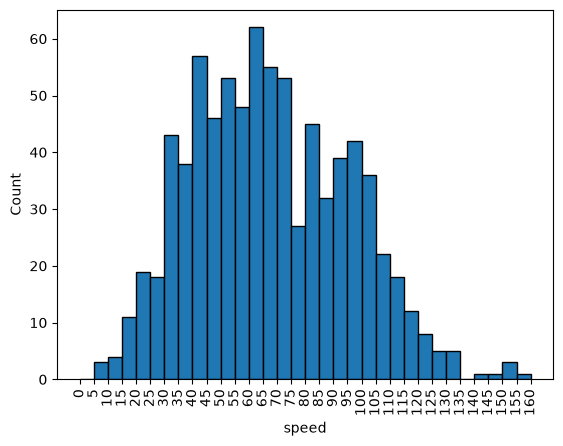

In [39]:
# Define bin edges for the histogram based on the 'speed' column

bin_edges = np.arange(0, pokemon['speed'].max() + 1, 5)

sb.histplot(data=pokemon, x='speed', bins=bin_edges, alpha=1)

plt.xticks(bin_edges, rotation=90);

Plot two histograms side-by-side
When creating histograms, it's useful to play around with different bin widths to see what represents the data best. Too many bins, and you may see too much noise that interferes with the identification of the underlying signal. Too few bins, and you may not be able to see the true signal in the first place.

Let's see a new example demonstrating a few new functions, pyplot.subplot() and pyplot.figure(). We will learn more in the upcoming concepts.

Example 5. Plot two histograms side-by-side

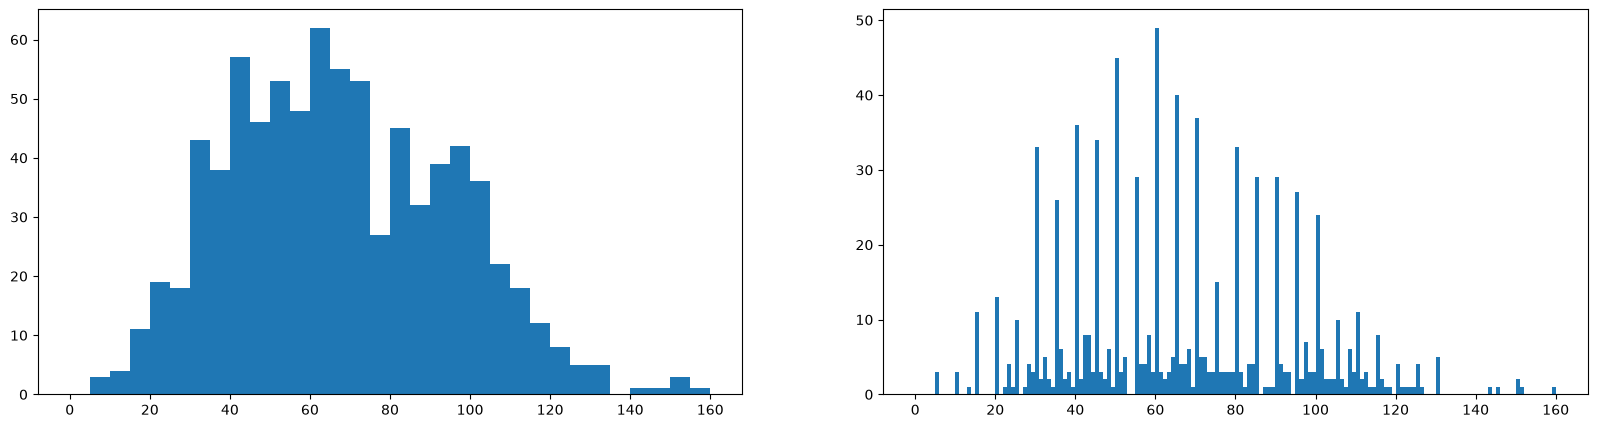

In [46]:
# Resize the chart, and have two plots side-by-side
# Set a larger figure size for subplots

plt.figure(figsize=[20, 5])

# Histogram on the left: example of too-large bin size
# 1 row, 2 columns, subplot 1

plt.subplot(1, 2, 1)
bins = np.arange(0, pokemon['speed'].max()+5, 5)
plt.hist(data=pokemon, x='speed', bins=bins)

# Histogram on the right: example of too-small bin size
# 1 row, 2 columns, subplot 2

plt.subplot(1,2,2)
bins = np.arange(0, pokemon['speed'].max()+1, 1)
plt.hist(data=pokemon, x='speed', bins=bins)

plt.show()

Here is how to read it, with numbers. Pokemon are shared out over the bins:

Right plot, 160 bins: 807 Pokemon ÷ 160 bins is about 5 per bin on average. With so few in each bin, chance matters a lot. One bin might get 3 Pokemon and the next 9, for no real reason. So the bars jump up and down, and the picture looks spiky. That up-and-down is noise, random wobble that hides the real pattern. Many bins also stay empty or nearly empty out in the fast tail past 100.
Left plot, 32 bins: 807 ÷ 32 is about 25 per bin. With 25 in each bar, the bars move together smoothly, so you can see the real shape: a hump in the middle of the speed range that thins out toward both ends and has a few very fast Pokemon far on the right.

That’s the lesson’s point. A wide bin hides detail. A very narrow bin turns the picture into noise. The best width sits in the middle, wide enough to smooth out chance, narrow enough to show the shape.

Summary of Histograms
In summary, if your exploration is only interested in the histogram depiction of the data and not the additional functionality offered by Seaborn's histplot, then you might be better off just using Matplotlib's hist function for simplicity. On the other hand, if you want a quick start on customizing bins or adding a kernel density estimate (KDE) curve to your histogram, Seaborn's histplot is a great choice to quickly visualize and fine-tune your data representation.